# CNOT Primitive XZ Hub
This file contains analysis for CNOT Primitive XZ hub results (initial scan and full scan).

The hub (target) does `N = c L` noisy CNOTs with fresh partners (controls), `k` ordinary rounds apart at every size, so the gate density `1/(k + 1)` and the circuit's aspect ratio are fixed. The target error rate is the hub's final logical failure (X or Z); the control error rate is the probability that at least one partner fails.

Contents:

1. **Initial scan**: coarse scans (`L = 5, 7, 9`, `N = L`) that located each gap's threshold.
2. **Full scan**: `L = 5-13`, `N = L` and `2L`, `10^5` trials per point, for `k = 0, 1, 2, 5, 10`: error rates, thresholds, the `L = 9` check, the error rate per CNOT, and the control error rate by partner index.
3. **Findings**.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

# Work whether Jupyter starts in projects/mp-decoder or its notebooks directory.
PROJECT_DIR = next(
    (
        path
        for path in (Path.cwd(), Path.cwd().parent)
        if (path / "notebooks/analysis_utils.py").is_file()
    ),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Run this notebook from projects/mp-decoder or projects/mp-decoder/notebooks."
    )
sys.path.insert(0, str(PROJECT_DIR / "notebooks"))

from analysis_utils import (
    P_MAX_BLOCK,
    RateEstimate,
    display_finite_size_scaling_fit,
    display_fit_summary,
    fit_finite_size_scaling,
    fit_lambda,
    last_crossing,
    load_ft_scan,
    parse_result_file,
    rates_as_scan,
    single_point_rate,
)

DATA_DIR = PROJECT_DIR / "results/cnot_primitive_xz/hub"
FAILURE_FIELDS = {
    "target": "hub_failures",
    "control": "partner_failure_trials",
    "target_x": "hub_x_failures",
    "target_z": "hub_z_failures",
}
# Initial and full scans share k_<k>/NL/; the stop tag in the file name tells them apart.
INITIAL_PATTERN = "2d_XZ_hub_*_hubfail*.txt"  # capped on hub failures
FULL_PATTERN = "2d_XZ_hub_*_trials*.txt"  # fixed 10^5 trials per point (RCC full scans)
MEMORY_PC = 0.0179  # memory threshold, notebooks/cnot_primitive_xz_memory_analysis.ipynb
SHOW_FIT_DETAILS = False  # True: show every fit's table and scaling collapse


def scan_p_values(gap, n_dir, pattern, L_values):
    # p values with results at every size
    by_L = {}
    for path in (DATA_DIR / f"k_{gap}" / n_dir).glob(pattern):
        record = parse_result_file(path)
        by_L.setdefault(int(record["L"]), set()).add(round(record["p"], 6))
    return sorted(set.intersection(*[by_L.get(L, set()) for L in L_values]))


def load_hub_scan(gap, n_dir, p_values, L_values, label, pattern=FULL_PATTERN):
    # n_dir: "NL" (N = L) or "N2L" (N = 2L)
    return load_ft_scan(
        DATA_DIR / f"k_{gap}" / n_dir,
        p_values=p_values,
        L_values=L_values,
        expected_repeats=None,
        result_pattern=pattern,
        success_field="Ft",
        failure_fields=FAILURE_FIELDS,
        scan_label=label,
    )


def plot_rate_panels(panels, ylabel, ncols=2):
    # panels: list of (scan, rate_name, title); one panel each, as plot_rate_scan draws it
    nrows = -(-len(panels) // ncols)
    _, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.4 * nrows), squeeze=False)
    for ax, (scan, rate_name, title) in zip(axes.flat, panels):
        estimate = scan.rate(rate_name)
        for l_idx, cur_l in enumerate(scan.L_values):
            ax.errorbar(scan.p_values, estimate.values[l_idx], yerr=estimate.errors[l_idx],
                        fmt="o-", capsize=3, label=f"L = {cur_l}")
        ax.set_yscale("log")
        ax.set_xlabel("p")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.legend(fontsize=8)
    for ax in list(axes.flat)[len(panels):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def crossings(scan, rate_name, pairs):
    values = scan.rate(rate_name).values
    index = {L: i for i, L in enumerate(scan.L_values)}
    return {pair: last_crossing(scan.p_values, values[index[pair[0]]], values[index[pair[1]]]) for pair in pairs}


fmt_pc = lambda c: "–" if c is None else f"{100 * c:.3f}"

## Initial scan
`L = 5, 7, 9`, `N = L`; coarse `p` grids that located each gap's threshold (`jobs/cnot_primitive_xz_hub_initial_scan.sh`; `k = 0, 3` were local runs). These crossings are superseded by the full scan below: with three small sizes, and `L = 9` running worse than its neighbours, they come out low.

In [2]:
initial_gaps = [0, 2, 3, 5, 10]
initial_L_values = [5, 7, 9]
initial_scans = {}
rows = ["| k | p values | trials per point |", "| --- | --- | --- |"]
for gap in initial_gaps:
    p_values = scan_p_values(gap, "NL", INITIAL_PATTERN, initial_L_values)
    initial_scans[gap] = load_hub_scan(gap, "NL", p_values, initial_L_values, f"XZ hub k = {gap} initial scan", pattern=INITIAL_PATTERN)
    trials = initial_scans[gap].trials
    rows.append(f"| {gap} | {100 * p_values[0]:.2f}-{100 * p_values[-1]:.2f}% ({len(p_values)}) | {int(trials.min())}-{int(trials.max())} |")
display(Markdown("\n".join(rows)))

| k | p values | trials per point |
| --- | --- | --- |
| 0 | 0.15-0.50% (7) | 4076-10000 |
| 2 | 0.15-1.20% (12) | 1073-10000 |
| 3 | 0.50-1.20% (7) | 1622-9232 |
| 5 | 0.15-1.20% (12) | 1077-10000 |
| 10 | 0.15-1.20% (12) | 1077-10000 |

### Target and control error rates

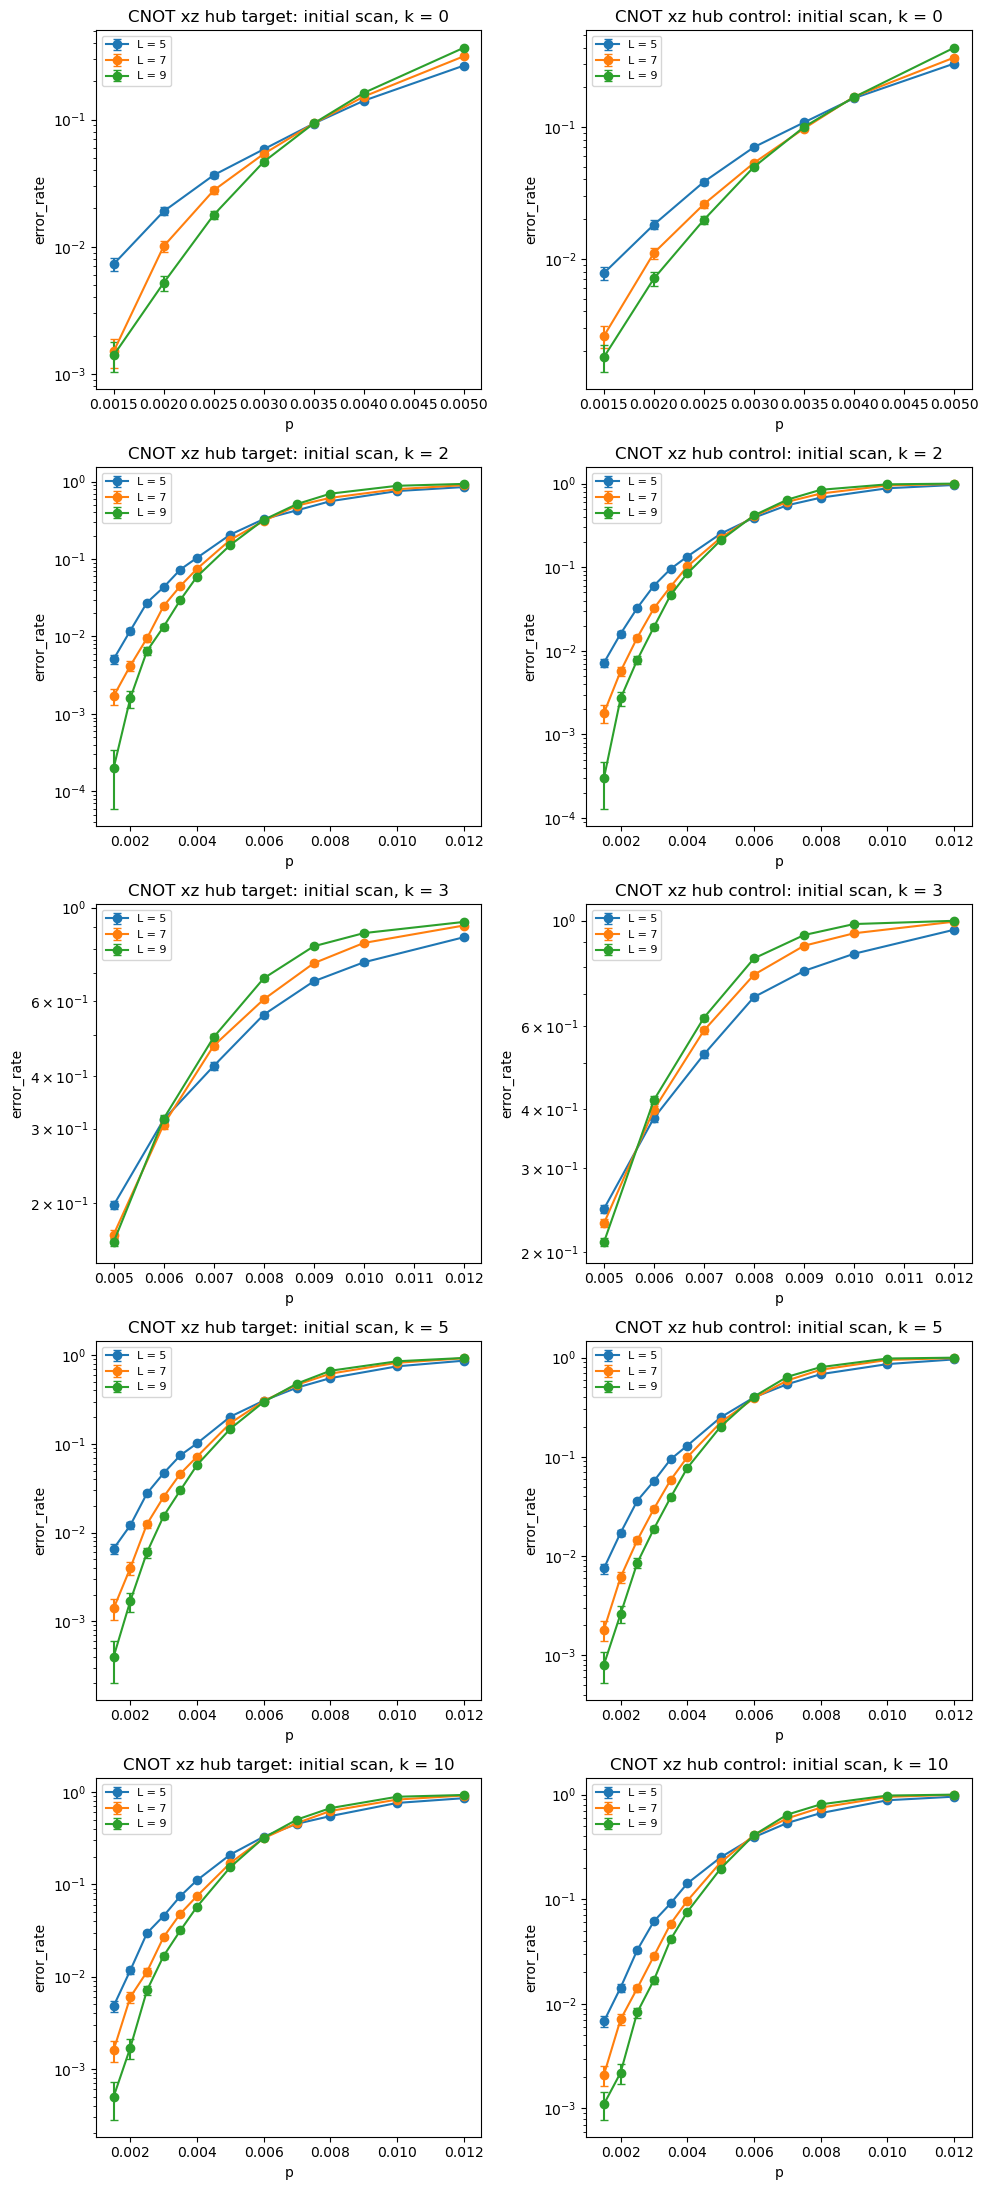

**Pairwise crossings (%)**

| k | target, 5/7 | target, 7/9 | control, 5/7 | control, 7/9 |
| --- | --- | --- | --- | --- |
| 0 | 0.349 | 0.349 | 0.386 | 0.402 |
| 2 | 0.622 | 0.570 | 0.560 | 0.568 |
| 3 | 0.615 | 0.540 | 0.551 | 0.551 |
| 5 | 0.610 | 0.630 | 0.614 | 0.557 |
| 10 | 0.660 | 0.581 | 0.559 | 0.596 |

In [3]:
panels = []
for gap, scan in initial_scans.items():
    panels.append((scan, "target", f"CNOT xz hub target: initial scan, k = {gap}"))
    panels.append((scan, "control", f"CNOT xz hub control: initial scan, k = {gap}"))
plot_rate_panels(panels, ylabel="error_rate")

rows = ["| k | target, 5/7 | target, 7/9 | control, 5/7 | control, 7/9 |", "| --- | --- | --- | --- | --- |"]
for gap, scan in initial_scans.items():
    target, control = crossings(scan, "target", [(5, 7), (7, 9)]), crossings(scan, "control", [(5, 7), (7, 9)])
    rows.append(f"| {gap} | " + " | ".join(fmt_pc(c) for c in [*target.values(), *control.values()]) + " |")
display(Markdown("**Pairwise crossings (%)**\n\n" + "\n".join(rows)))

## Full scan
`L = 5-13`, `N = L` and `N = 2L`, a fixed `10^5` trials per point (`jobs/cnot_primitive_xz_hub_full_scan.sh`; four `_rep<r>` files of `2.5 * 10^4` trials each, summed). The first local `k = 1` run (at most `10^4` trials per point) is superseded by the RCC `k = 1` run and not used here.

In [4]:
full_gaps = [0, 1, 2, 5, 10]
full_L_values = [5, 7, 9, 11, 13]
cnot_dirs = {"N = L": "NL", "N = 2L": "N2L"}

full_scans = {}
rows = ["| k | N | p values | trials per point |", "| --- | --- | --- | --- |"]
for gap in full_gaps:
    for tag, n_dir in cnot_dirs.items():
        p_values = scan_p_values(gap, n_dir, FULL_PATTERN, full_L_values)
        full_scans[gap, tag] = load_hub_scan(gap, n_dir, p_values, full_L_values, f"XZ hub k = {gap}, {tag} full scan")
        trials = full_scans[gap, tag].trials
        rows.append(f"| {gap} | {tag} | {100 * p_values[0]:.2f}-{100 * p_values[-1]:.2f}% ({len(p_values)}) | {int(trials.min())}-{int(trials.max())} |")
display(Markdown("\n".join(rows)))

| k | N | p values | trials per point |
| --- | --- | --- | --- |
| 0 | N = L | 0.20-0.50% (11) | 100000-100000 |
| 0 | N = 2L | 0.20-0.50% (11) | 100000-100000 |
| 1 | N = L | 0.25-0.80% (11) | 100000-100000 |
| 1 | N = 2L | 0.25-0.80% (11) | 100000-100000 |
| 2 | N = L | 0.30-0.85% (11) | 100000-100000 |
| 2 | N = 2L | 0.30-0.85% (11) | 100000-100000 |
| 5 | N = L | 0.30-0.85% (11) | 100000-100000 |
| 5 | N = 2L | 0.30-0.85% (11) | 100000-100000 |
| 10 | N = L | 0.30-0.85% (11) | 100000-100000 |
| 10 | N = 2L | 0.30-0.85% (11) | 100000-100000 |

### Target error rate

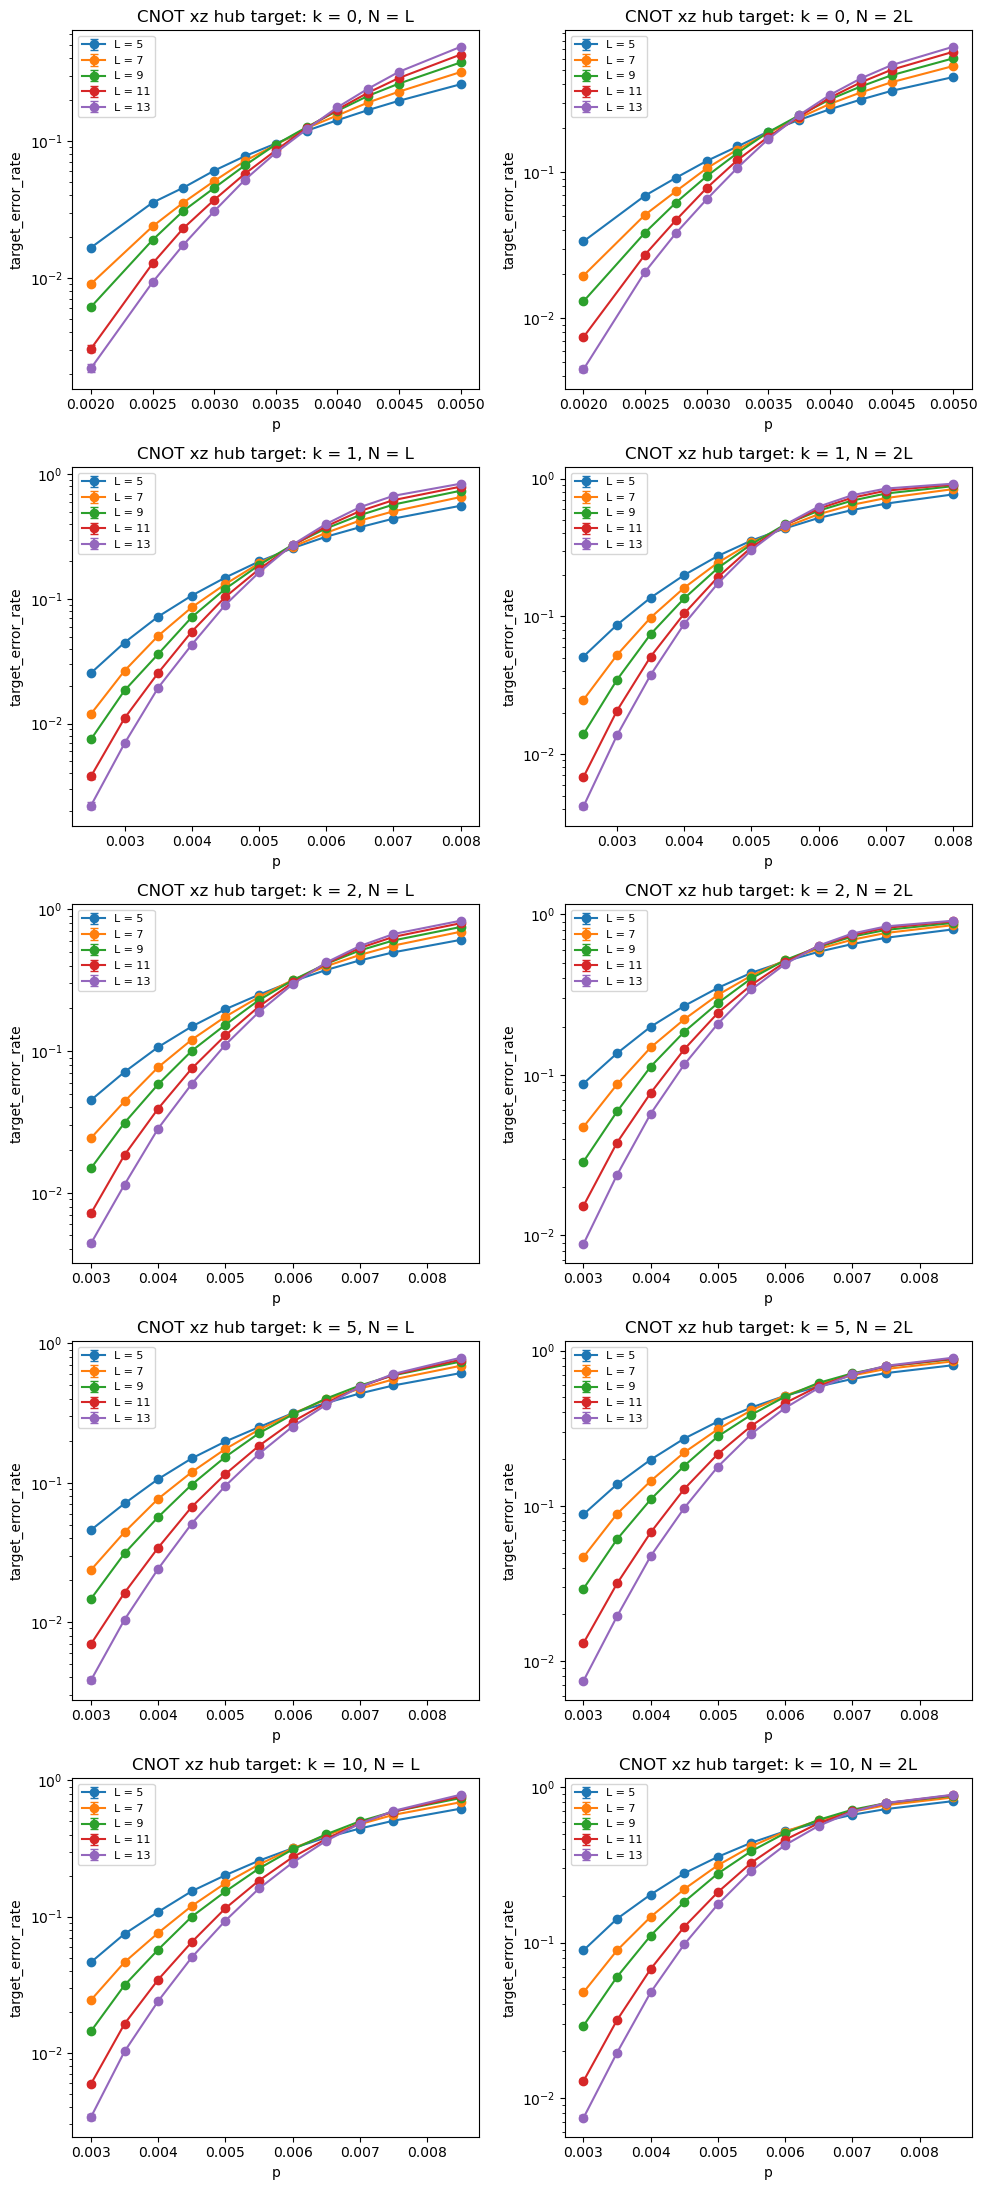

In [5]:
plot_rate_panels(
    [(scan, "target", f"CNOT xz hub target: k = {gap}, {tag}") for (gap, tag), scan in full_scans.items()],
    ylabel="target_error_rate",
)

### Control error rate

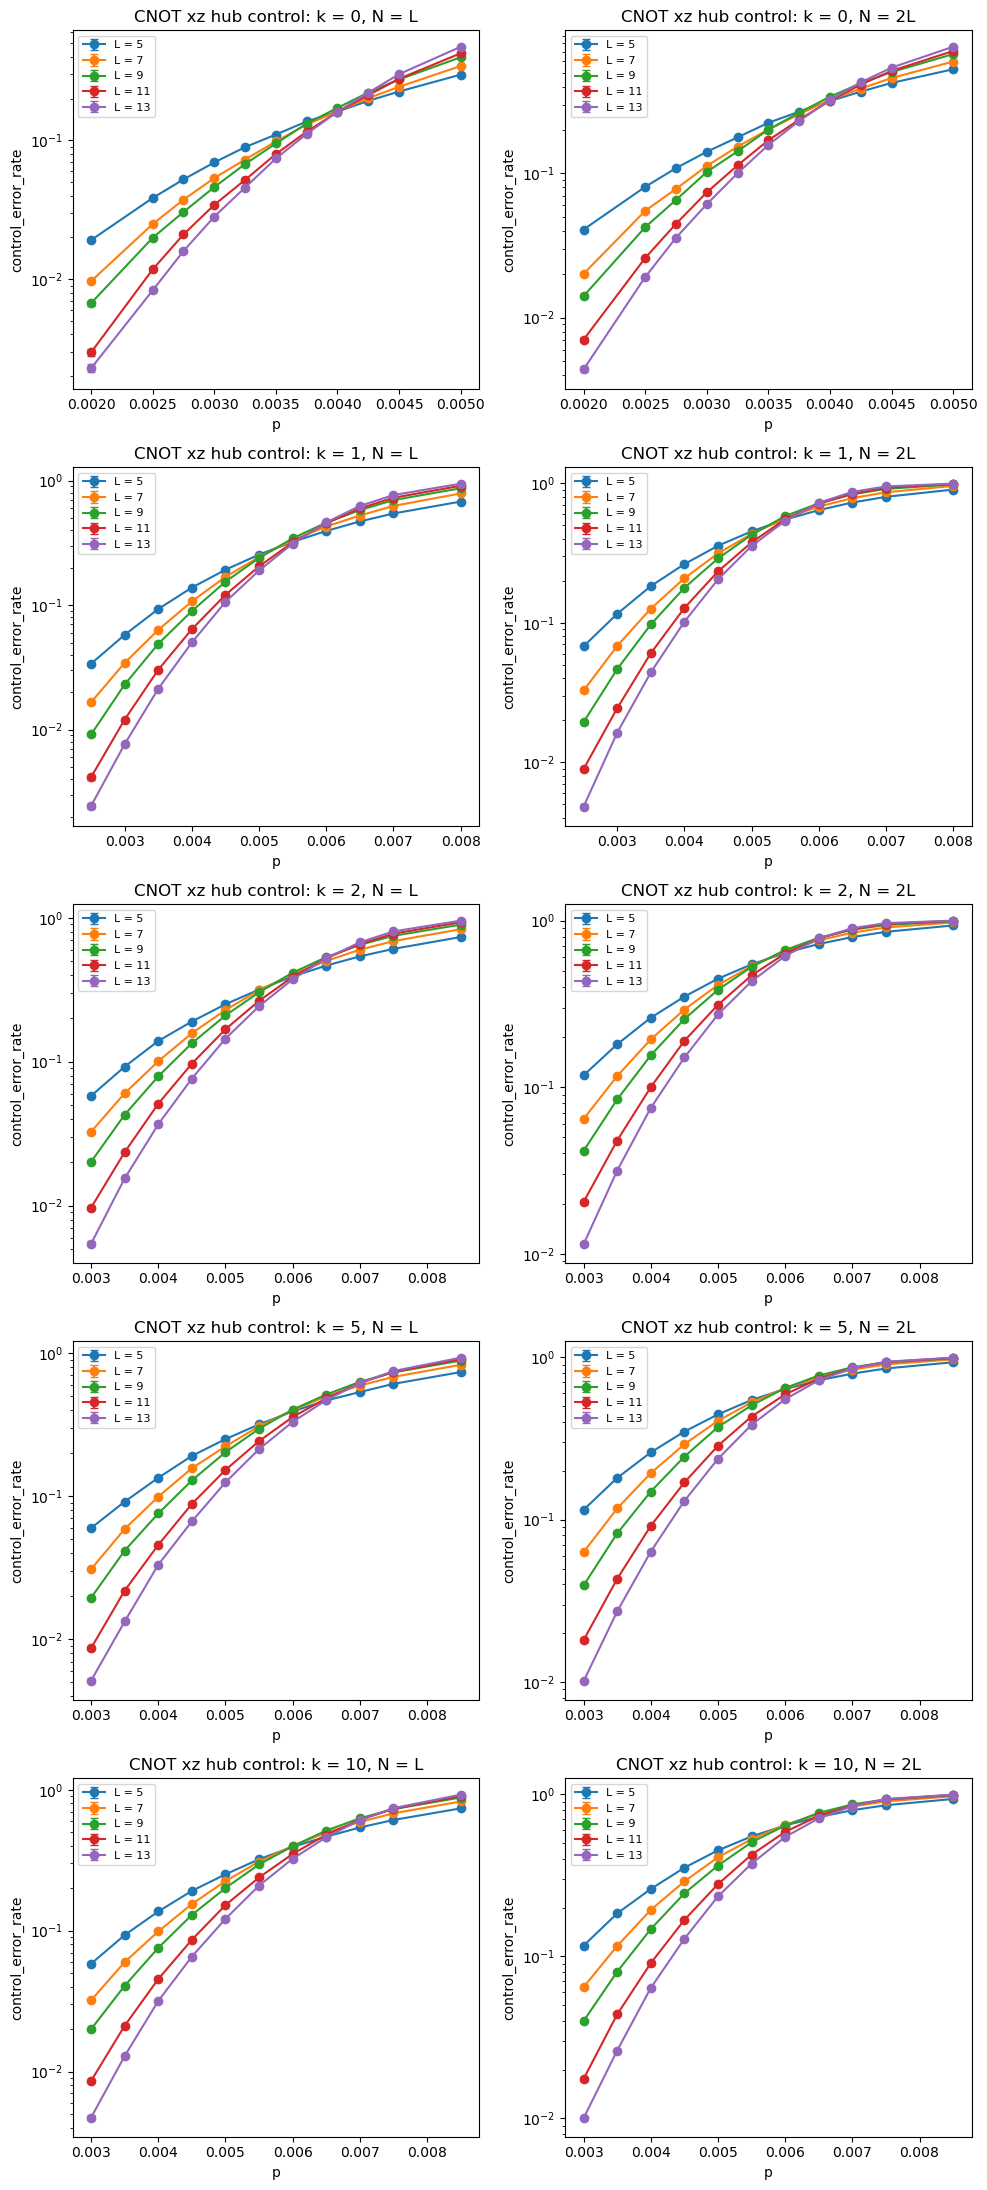

In [6]:
plot_rate_panels(
    [(scan, "control", f"CNOT xz hub control: k = {gap}, {tag}") for (gap, tag), scan in full_scans.items()],
    ylabel="control_error_rate",
)

### Thresholds
Degree-2 finite-size fits without `L = 9` (see the next section) and without the smallest size, i.e. `L = 7, 11, 13`, over the five grid values of `p` nearest the 11/13 crossing. The range column spans the pairwise crossings 7/11, 7/13 and 11/13 and the same fit with `L = 9` included; the `chi2/dof` values show that finite-size drift, not statistics, sets the uncertainty. The target is also split by sector: X (absorbs the partners' X histories) and Z.

| k | N | rate | p_c (%) | p_c / memory | chi2/dof (p-value) | range (%) |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | N = L | target | 0.374 ± 0.001 | 0.21 | 10/10 (0.45) | 0.375-0.382 |
| 0 | N = L | control | 0.402 ± 0.001 | 0.22 | 26/10 (0.00) | 0.397-0.405 |
| 0 | N = L | target X | 0.357 ± 0.001 | 0.20 | 9/10 (0.54) | 0.355-0.370 |
| 0 | N = L | target Z | 0.412 ± 0.001 | 0.23 | 12/10 (0.29) | 0.408-0.414 |
| 0 | N = 2L | target | 0.367 ± 0.001 | 0.21 | 13/10 (0.20) | 0.362-0.369 |
| 0 | N = 2L | control | 0.398 ± 0.001 | 0.22 | 34/10 (0.00) | 0.388-0.404 |
| 0 | N = 2L | target X | 0.351 ± 0.001 | 0.20 | 19/10 (0.04) | 0.347-0.352 |
| 0 | N = 2L | target Z | 0.410 ± 0.001 | 0.23 | 12/10 (0.28) | 0.411-0.412 |
| 1 | N = L | target | 0.537 ± 0.001 | 0.30 | 51/10 (0.00) | 0.536-0.538 |
| 1 | N = L | control | 0.566 ± 0.001 | 0.32 | 110/10 (0.00) | 0.567-0.573 |
| 1 | N = L | target X | 0.517 ± 0.001 | 0.29 | 13/10 (0.22) | 0.517-0.520 |
| 1 | N = L | target Z | 0.586 ± 0.002 | 0.33 | 9/10 (0.52) | 0.584-0.597 |
| 1 | N = 2L | target | 0.530 ± 0.001 | 0.30 | 282/10 (0.00) | 0.532-0.539 |
| 1 | N = 2L | control | 0.557 ± 0.001 | 0.31 | 326/10 (0.00) | 0.559-0.579 |
| 1 | N = 2L | target X | 0.512 ± 0.001 | 0.29 | 91/10 (0.00) | 0.511-0.518 |
| 1 | N = 2L | target Z | 0.578 ± 0.001 | 0.32 | 96/10 (0.00) | 0.579-0.587 |
| 2 | N = L | target | 0.618 ± 0.001 | 0.35 | 93/10 (0.00) | 0.620-0.627 |
| 2 | N = L | control | 0.625 ± 0.001 | 0.35 | 155/10 (0.00) | 0.621-0.652 |
| 2 | N = L | target X | 0.598 ± 0.001 | 0.33 | 27/10 (0.00) | 0.597-0.604 |
| 2 | N = L | target Z | 0.672 ± 0.002 | 0.38 | 30/10 (0.00) | 0.666-0.691 |
| 2 | N = 2L | target | 0.618 ± 0.001 | 0.35 | 106/10 (0.00) | 0.618-0.638 |
| 2 | N = 2L | control | 0.625 ± 0.001 | 0.35 | 191/10 (0.00) | 0.626-0.647 |
| 2 | N = 2L | target X | 0.595 ± 0.001 | 0.33 | 130/10 (0.00) | 0.596-0.612 |
| 2 | N = 2L | target Z | 0.671 ± 0.001 | 0.38 | 90/10 (0.00) | 0.662-0.685 |
| 5 | N = L | target | 0.685 ± 0.001 | 0.38 | 85/10 (0.00) | 0.680-0.698 |
| 5 | N = L | control | 0.668 ± 0.001 | 0.37 | 304/10 (0.00) | 0.670-0.702 |
| 5 | N = L | target X | 0.664 ± 0.002 | 0.37 | 38/10 (0.00) | 0.664-0.673 |
| 5 | N = L | target Z | 0.733 ± 0.002 | 0.41 | 39/10 (0.00) | 0.723-0.761 |
| 5 | N = 2L | target | 0.681 ± 0.001 | 0.38 | 54/10 (0.00) | 0.680-0.707 |
| 5 | N = 2L | control | 0.676 ± 0.001 | 0.38 | 795/10 (0.00) | 0.670-0.711 |
| 5 | N = 2L | target X | 0.659 ± 0.002 | 0.37 | 105/10 (0.00) | 0.656-0.679 |
| 5 | N = 2L | target Z | 0.732 ± 0.002 | 0.41 | 113/10 (0.00) | 0.725-0.762 |
| 10 | N = L | target | 0.690 ± 0.001 | 0.39 | 139/10 (0.00) | 0.687-0.718 |
| 10 | N = L | control | 0.676 ± 0.001 | 0.38 | 275/10 (0.00) | 0.673-0.712 |
| 10 | N = L | target X | 0.674 ± 0.002 | 0.38 | 39/10 (0.00) | 0.670-0.686 |
| 10 | N = L | target Z | 0.742 ± 0.002 | 0.41 | 58/10 (0.00) | 0.742-0.770 |
| 10 | N = 2L | target | 0.698 ± 0.001 | 0.39 | 84/10 (0.00) | 0.692-0.731 |
| 10 | N = 2L | control | 0.686 ± 0.001 | 0.38 | 478/10 (0.00) | 0.683-0.720 |
| 10 | N = 2L | target X | 0.676 ± 0.002 | 0.38 | 77/10 (0.00) | 0.670-0.690 |
| 10 | N = 2L | target Z | 0.749 ± 0.002 | 0.42 | 133/10 (0.00) | 0.741-0.787 |

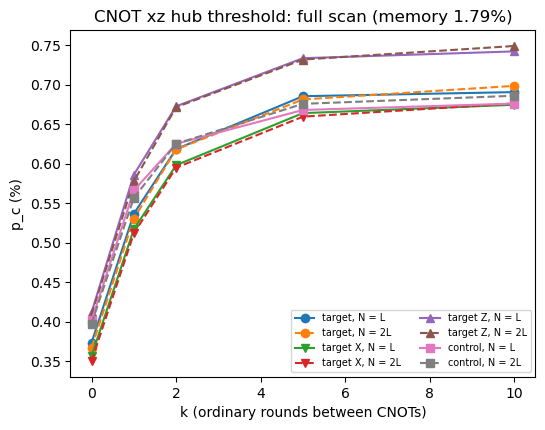

In [7]:
fit_L_values = [7, 11, 13]
fit_degree = 2
rate_labels = {"target": "target", "control": "control", "target_x": "target X", "target_z": "target Z"}


def threshold_fit(scan, rate_name, L_values, window, label):
    index = [list(scan.L_values).index(L) for L in L_values]
    estimate = scan.rate(rate_name)
    sub = rates_as_scan({rate_name: RateEstimate(estimate.values[index], estimate.errors[index])},
                        L_values=L_values, p_values=scan.p_values, label=label)
    return fit_finite_size_scaling(sub, rate_name=rate_name, label=label, polynomial_degree=fit_degree,
                                   fit_p_range=window, min_L=min(L_values))


full_fits, thresholds = [], {}
rows = ["| k | N | rate | p_c (%) | p_c / memory | chi2/dof (p-value) | range (%) |", "| --- | --- | --- | --- | --- | --- | --- |"]
for (gap, tag), scan in full_scans.items():
    for rate_name, rate_label in rate_labels.items():
        cross = crossings(scan, rate_name, [(7, 11), (7, 13), (11, 13)])
        nearest = sorted(sorted(scan.p_values, key=lambda p: abs(p - cross[11, 13]))[:5])
        window = (nearest[0], nearest[-1])
        fit = threshold_fit(scan, rate_name, fit_L_values, window, f"XZ hub full scan — {rate_label}, k = {gap}, {tag}")
        with_9 = threshold_fit(scan, rate_name, [7, 9, 11, 13], window, "with L = 9")
        span = [c for c in cross.values() if c is not None] + [with_9.pc]
        thresholds[gap, tag, rate_name] = fit
        if rate_name in ("target", "control"):
            full_fits.append(fit)
        rows.append(f"| {gap} | {tag} | {rate_label} | {100 * fit.pc:.3f} ± {100 * fit.pc_error:.3f} | {fit.pc / MEMORY_PC:.2f} | "
                    f"{fit.chi2:.0f}/{fit.dof} ({fit.p_value:.2f}) | {100 * min(span):.3f}-{100 * max(span):.3f} |")
display(Markdown("\n".join(rows)))

_, ax = plt.subplots(figsize=(6, 4.5))
for rate_name, marker in (("target", "o"), ("target_x", "v"), ("target_z", "^"), ("control", "s")):
    for tag, style in (("N = L", "-"), ("N = 2L", "--")):
        ax.plot(full_gaps, [100 * thresholds[gap, tag, rate_name].pc for gap in full_gaps], marker + style,
                label=f"{rate_labels[rate_name]}, {tag}")
ax.set_xlabel("k (ordinary rounds between CNOTs)")
ax.set_ylabel("p_c (%)")
ax.set_title(f"CNOT xz hub threshold: full scan (memory {100 * MEMORY_PC:.2f}%)")
ax.legend(fontsize=7, ncol=2)
plt.show()

### The `L = 9` check
`P(L = 9) / sqrt(P(L = 7) P(L = 11))` for the target error rate at `N = L`; 1 for a smooth size dependence. The memory full scan shows the same excess at `L = 9`.

In [8]:
show_p = [0.003, 0.004, 0.005]
rows = ["| k | " + " | ".join(f"p = {100 * p:.1f}%" for p in show_p) + " | near threshold |", "| --- |" + " --- |" * (len(show_p) + 1)]
for gap in full_gaps:
    scan = full_scans[gap, "N = L"]
    values = scan.rate("target").values
    ratio = values[2] / np.sqrt(values[1] * values[3])
    p_near = min(scan.p_values, key=lambda p: abs(p - thresholds[gap, "N = L", "target"].pc))
    cells = [f"{ratio[list(scan.p_values).index(p)]:.2f}" for p in show_p]
    rows.append(f"| {gap} | " + " | ".join(cells) + f" | {ratio[list(scan.p_values).index(p_near)]:.2f} (p = {100 * p_near:.2f}%) |")
display(Markdown("\n".join(rows)))

| k | p = 0.3% | p = 0.4% | p = 0.5% | near threshold |
| --- | --- | --- | --- | --- |
| 0 | 1.04 | 1.03 | 1.01 | 1.02 (p = 0.38%) |
| 1 | 1.08 | 1.04 | 1.02 | 1.03 (p = 0.55%) |
| 2 | 1.13 | 1.06 | 1.02 | 1.02 (p = 0.60%) |
| 5 | 1.14 | 1.11 | 1.08 | 1.04 (p = 0.70%) |
| 10 | 1.20 | 1.12 | 1.07 | 1.04 (p = 0.70%) |

### Target error rate per CNOT
`eps = P_max [1 - (1 - P / P_max)^(1/N)]` (`P_max = 15/16`), from `N = L`; `N = 2L` gives the same `eps` when the circuit is in steady state. `Lambda` comes from `ln eps` against `(L + 1)/2` over `L = 5-13`.

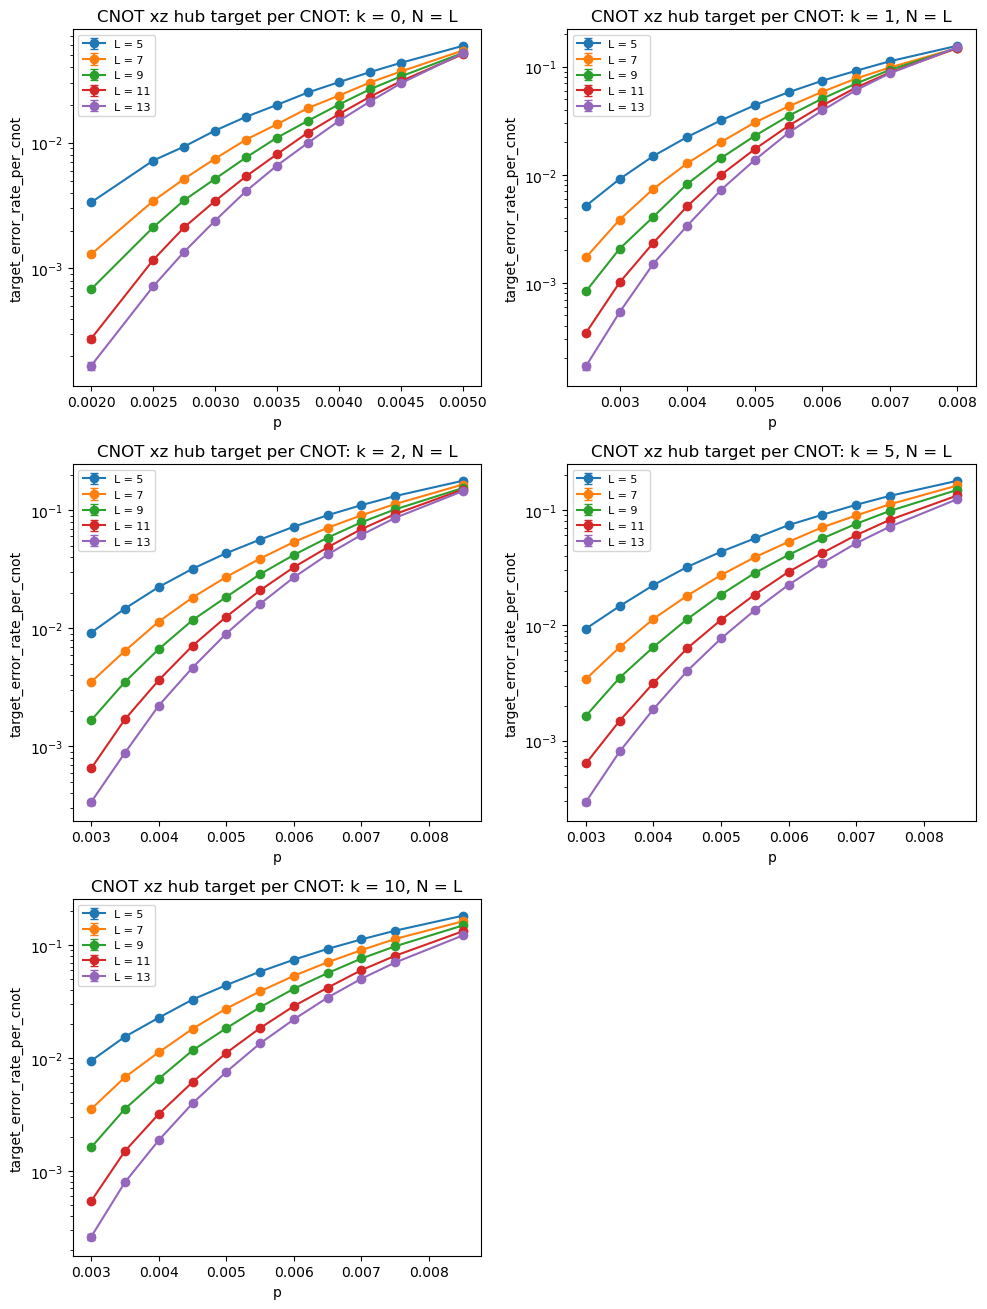

**Per CNOT at `N = L` (`N = 2L` in brackets)**

| k | eps, L = 13, p = 0.3% | eps, L = 13, p = 0.4% | eps, L = 13, p = 0.5% | Lambda, p = 0.3% | Lambda, p = 0.4% | Lambda, p = 0.5% |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | 0.00240 [0.00260] | 0.01487 [0.01604] | 0.05130 [0.05205] | 1.51 | 1.19 | 1.03 |
| 1 | 0.00054 [0.00053] | 0.00338 [0.00356] | 0.01370 [0.01399] | 2.05 | 1.61 | 1.34 |
| 2 | 0.00034 [0.00034] | 0.00222 [0.00227] | 0.00903 [0.00902] | 2.35 | 1.80 | 1.48 |
| 5 | 0.00029 [0.00029] | 0.00188 [0.00187] | 0.00767 [0.00760] | 2.41 | 1.87 | 1.55 |
| 10 | 0.00026 [0.00029] | 0.00187 [0.00188] | 0.00754 [0.00748] | 2.49 | 1.88 | 1.56 |

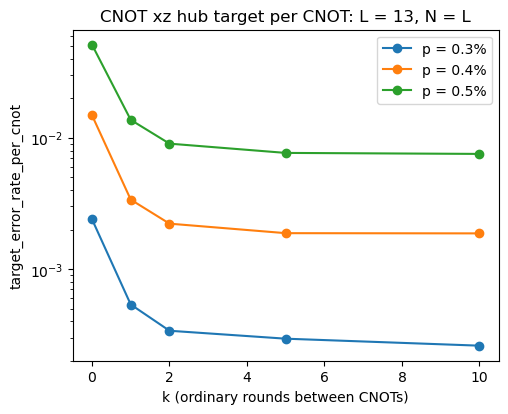

In [9]:
def per_cnot(scan, c):
    target = scan.rate("target")
    eps, eps_err = np.full_like(target.values, np.nan), np.full_like(target.values, np.nan)
    for i, L in enumerate(scan.L_values):
        for j in range(len(scan.p_values)):
            trials = scan.trials[i, j]
            if 0 < target.values[i, j] < P_MAX_BLOCK:
                eps[i, j], eps_err[i, j] = single_point_rate(target.values[i, j] * trials, trials, c * L, p_max=P_MAX_BLOCK)
    return RateEstimate(eps, eps_err)


eps = {(gap, tag): per_cnot(full_scans[gap, tag], c) for gap in full_gaps for tag, c in (("N = L", 1), ("N = 2L", 2))}
plot_rate_panels(
    [(rates_as_scan({"target": eps[gap, "N = L"]}, L_values=full_L_values, p_values=full_scans[gap, "N = L"].p_values, label="per CNOT"),
      "target", f"CNOT xz hub target per CNOT: k = {gap}, N = L") for gap in full_gaps],
    ylabel="target_error_rate_per_cnot",
)

common_p = [0.003, 0.004, 0.005]   # in every gap's grid
rows = ["| k | " + " | ".join(f"eps, L = 13, p = {100 * p:.1f}%" for p in common_p) + " | " +
        " | ".join(f"Lambda, p = {100 * p:.1f}%" for p in common_p) + " |", "| --- |" + " --- |" * (2 * len(common_p))]
for gap in full_gaps:
    p_values = list(full_scans[gap, "N = L"].p_values)
    cells, lams = [], []
    for p in common_p:
        j = p_values.index(p)
        e1, e2 = eps[gap, "N = L"], eps[gap, "N = 2L"]
        cells.append(f"{e1.values[-1, j]:.5f} [{e2.values[-1, j]:.5f}]")
        lams.append(f"{fit_lambda(full_L_values, e1.values[:, j], e1.errors[:, j]).Lambda:.2f}")
    rows.append(f"| {gap} | " + " | ".join(cells) + " | " + " | ".join(lams) + " |")
display(Markdown("**Per CNOT at `N = L` (`N = 2L` in brackets)**\n\n" + "\n".join(rows)))

_, ax = plt.subplots(figsize=(5.5, 4.3))
for p in common_p:
    ax.plot(full_gaps, [eps[gap, "N = L"].values[-1, list(full_scans[gap, "N = L"].p_values).index(p)] for gap in full_gaps],
            "o-", label=f"p = {100 * p:.1f}%")
ax.set_yscale("log")
ax.set_xlabel("k (ordinary rounds between CNOTs)")
ax.set_ylabel("target_error_rate_per_cnot")
ax.set_title("CNOT xz hub target per CNOT: L = 13, N = L")
ax.legend()
plt.show()

### Control error rate by partner index
Failures of partner `j`, pooled over `p` and divided by their mean over partners (`N = L`). Partner `j` carries the hub's Z errors made before gate `j`, so its final rate grows with `j`; its own Z faults (frame snapshots) show whether the hub's history is the same at every gate.

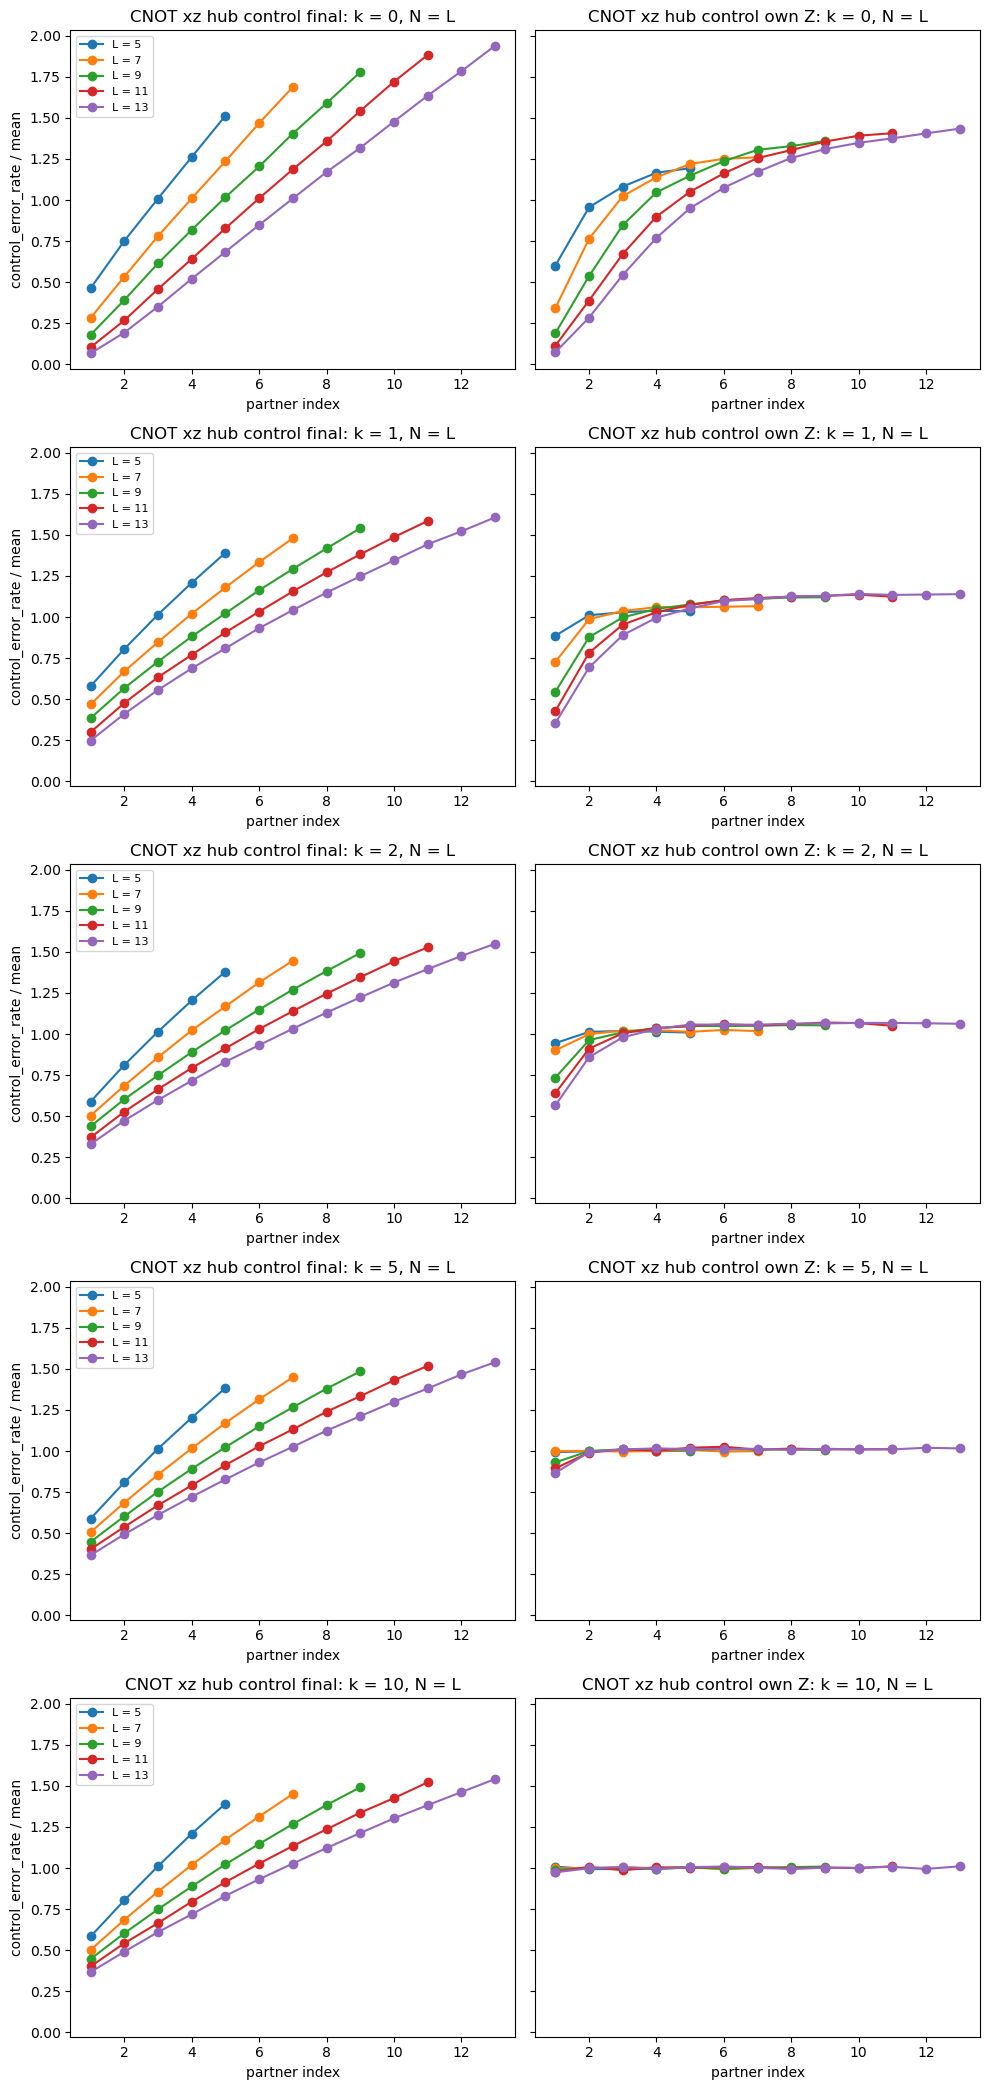

In [10]:
profile_keys = {"final": "partner_failures_by_index", "own Z": "partner_z_own_failures_by_index"}
_, axes = plt.subplots(len(full_gaps), 2, figsize=(10, 4.2 * len(full_gaps)), sharey=True)
for row, gap in zip(axes, full_gaps):
    records = [parse_result_file(path) for path in (DATA_DIR / f"k_{gap}" / "NL").glob(FULL_PATTERN)]
    for ax, (tag, key) in zip(row, profile_keys.items()):
        for L in full_L_values:
            counts = sum(np.asarray(r[key], dtype=float) for r in records if int(r["L"]) == L)
            ax.plot(np.arange(1, L + 1), counts / counts.mean(), "o-", label=f"L = {L}")
        ax.set_xlabel("partner index")
        ax.set_title(f"CNOT xz hub control {tag}: k = {gap}, N = L")
    row[0].set_ylabel("control_error_rate / mean")
    row[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Fit summary

In [11]:
display_fit_summary(
    full_fits,
    title="XZ hub full-scan fit summary",
)
if SHOW_FIT_DETAILS:
    for fit in full_fits:
        display_finite_size_scaling_fit(fit, "error_rate")

## XZ hub full-scan fit summary

| Timing and block | degree | $p_c$ | $p_c$ (%) | $\nu$ | $\chi^2 / \mathrm{dof}$ | fit $p$-value |
|---|---:|---:|---:|---:|---:|---:|
| XZ hub full scan — target, k = 0, N = L | 2 | 0.00374(1) | 0.374(1) | 1.37(4) | 0.99 | 0.446 |
| XZ hub full scan — control, k = 0, N = L | 2 | 0.00402(1) | 0.402(1) | 1.39(4) | 2.61 | 0.00362 |
| XZ hub full scan — target, k = 0, N = 2L | 2 | 0.003675(8) | 0.3675(8) | 1.40(3) | 1.35 | 0.199 |
| XZ hub full scan — control, k = 0, N = 2L | 2 | 0.003979(8) | 0.3979(8) | 1.55(3) | 3.42 | 0.000172 |
| XZ hub full scan — target, k = 1, N = L | 2 | 0.00537(1) | 0.537(1) | 1.46(2) | 5.14 | 1.49e-07 |
| XZ hub full scan — control, k = 1, N = L | 2 | 0.00566(1) | 0.566(1) | 1.54(2) | 10.99 | 5.51e-19 |
| XZ hub full scan — target, k = 1, N = 2L | 2 | 0.00530(1) | 0.530(1) | 1.60(2) | 28.24 | 8.18e-55 |
| XZ hub full scan — control, k = 1, N = 2L | 2 | 0.005567(9) | 0.5567(9) | 1.52(2) | 32.59 | 5.1e-64 |
| XZ hub full scan — target, k = 2, N = L | 2 | 0.00618(1) | 0.618(1) | 1.46(2) | 9.28 | 1.5e-15 |
| XZ hub full scan — control, k = 2, N = L | 2 | 0.00625(1) | 0.625(1) | 1.52(2) | 15.50 | 3.41e-28 |
| XZ hub full scan — target, k = 2, N = 2L | 2 | 0.00618(1) | 0.618(1) | 1.51(2) | 10.65 | 2.71e-18 |
| XZ hub full scan — control, k = 2, N = 2L | 2 | 0.006251(9) | 0.6251(9) | 1.50(2) | 19.13 | 1.06e-35 |
| XZ hub full scan — target, k = 5, N = L | 2 | 0.00685(1) | 0.685(1) | 1.66(3) | 8.49 | 5.56e-14 |
| XZ hub full scan — control, k = 5, N = L | 2 | 0.00668(1) | 0.668(1) | 1.58(2) | 30.37 | 2.61e-59 |
| XZ hub full scan — target, k = 5, N = 2L | 2 | 0.00681(1) | 0.681(1) | 1.47(3) | 5.36 | 5.71e-08 |
| XZ hub full scan — control, k = 5, N = 2L | 2 | 0.006756(9) | 0.6756(9) | 1.36(2) | 79.47 | 2.78e-164 |
| XZ hub full scan — target, k = 10, N = L | 2 | 0.00690(1) | 0.690(1) | 1.66(3) | 13.94 | 5.63e-25 |
| XZ hub full scan — control, k = 10, N = L | 2 | 0.00676(1) | 0.676(1) | 1.58(2) | 27.48 | 3.31e-53 |
| XZ hub full scan — target, k = 10, N = 2L | 2 | 0.00698(1) | 0.698(1) | 1.65(3) | 8.38 | 8.81e-14 |
| XZ hub full scan — control, k = 10, N = 2L | 2 | 0.006858(9) | 0.6858(9) | 1.38(2) | 47.77 | 2.62e-96 |

## Findings

**The threshold rises with the gap and saturates near `k = 5`.** Main fits (`L = 7, 11, 13`); the range column above gives the systematic spread, about 0.01-0.03%.

| k | target, N = L / 2L (%) | target X / Z (%) | control (%) | target / memory |
| --- | --- | --- | --- | --- |
| 0 | 0.374 / 0.367 | 0.357 / 0.412 | 0.402 | 0.21 |
| 1 | 0.537 / 0.530 | 0.517 / 0.586 | 0.566 | 0.30 |
| 2 | 0.618 / 0.618 | 0.598 / 0.672 | 0.625 | 0.35 |
| 5 | 0.685 / 0.681 | 0.664 / 0.733 | 0.668 | 0.38 |
| 10 | 0.690 / 0.698 | 0.674 / 0.742 | 0.676 | 0.39 |

- `N = L` and `N = 2L` cross within 0.008% of each other, so the fixed-aspect threshold does not depend on the aspect ratio.
- The initial scans (`L <= 9`) put the plateau at 0.55-0.65%, which is low. For `k >= 2` the crossings drift upward with `L` (`k = 5`: 0.60% at 5/7, 0.70% at 11/13), so the large-`L` threshold may be a little higher still.

**Error per CNOT** at `p = 0.4%`, `L = 13`: 0.0149, 0.0034, 0.0022, 0.0019, 0.0019 for `k = 0, 1, 2, 5, 10`; `Lambda` at 0.4%: 1.19, 1.61, 1.80, 1.87, 1.88. Spacing the gates gains about 8x over back-to-back gates, and nothing beyond `k` of about 5.

**Why it saturates (inference).** After each gate the hub's Z history takes about 6-10 rounds to settle, comparable to the hub decoder's buffer depth (`Z = 4-7` rounds at these sizes).
- The partners' own Z faults rise over the first ~10 gates at `k = 0`, 4-5 gates at `k = 1`, and 2 at `k = 2`, and are flat for `k >= 5`.
- When gates come faster, each merge lands on history the decoder has not finished, and the error per gate rises.
- At `k = 0` the hub does not reach steady state within `N = L` (the error per CNOT is 4-8% higher at `N = 2L`); for `k >= 1` it does (ratio 0.97-1.00).

**The target's X sector limits the threshold** at every gap, crossing 0.06-0.07% below Z. X is the sector that absorbs the partners' X histories at each merge, so the merge rule, more than the hub's own noise, is the bottleneck. That is what the Y-junction rule would change.

**Controls.**
- Their any-partner threshold is close to the target's: slightly above it for `k <= 2`, slightly below for `k >= 5`.
- Partner `j`'s final failure grows linearly with `j`, because it carries the hub's Z errors from before gate `j`. At `p = 0.4%`, `L = 13`, the average partner fails 1.6-2.9x more often than its own faults alone.

**`L = 9` runs worse here too.** Its failure exceeds the neighbours' geometric mean by 2-4% near threshold and by up to 20% at `p = 0.3%`, growing with `k` (more idle rounds), as in the memory full scan. The main fits therefore leave it out.

**Caveats.**
- Even without `L = 9` the fits are poor for `k >= 1` (`chi2/dof` 3-30), a sign of finite-size drift beyond the quadratic ansatz.
- Sizes stop at `L = 13`.
- The two-qubit noise is `10p`, and the rule is the primitive merge.

**Next.**
- `L = 15-19` at `k = 2` and 5, to see where the drifting crossings settle.
- The Y-junction rule, aimed at the X-sector merge bottleneck when gates come faster than the hub's buffer clears.
- Optionally `k = 3`, to resolve the knee between `k = 2` and 5.